# TB chest X-ray screening: one model, three clinics, two kinds of drift

**The setting.** A TB programme screens adults with a chest X-ray. Anyone the model flags is sent for a
lab test (GeneXpert or culture). A **missed TB case** goes home untreated and keeps transmitting; a
**false alarm** costs a lab test. The programme wants to catch at least 90% of TB cases (WHO's target
for computer-aided detection: ≥ 90% sensitivity, ≥ 70% specificity).

**The data.** A real prospective study: Google and CIDRZ evaluated Google's TB AI on 1,828 adults at three
clinics in Lusaka, Zambia (Kazemzadeh et al., *NEJM AI*, 2024). Every participant had a chest X-ray **and**
a lab test, so we know who really had TB, and the study recorded HIV status. We use it to replay a
rollout, step by step, as if we were building our own model:

| Step | Who | What changes |
|---|---|---|
| 1 | Kanyama clinic, HIV-negative adults | nothing: we build and validate here |
| 2 | Chawama clinic, HIV-negative | a new clinic, **same X-ray machine** |
| 3 | Chainda South clinic, HIV-negative | a **different X-ray machine** (acquisition drift) |
| 4 | Kanyama clinic, **HIV-positive** adults | same machine, **different patients** (population shift) |

Steps 3 and 4 are the two kinds of drift. Watch which checks catch which.

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"      # keep MLflow's import message out of the output
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from mlflow.models import infer_signature
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import tb_helpers as tb

pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
people, X = tb.load_data()       # one row per participant (+ their X-ray's header facts); X = 1024 image features each
y = people.tb.to_numpy()         # 1 = bacteriologically confirmed TB (culture or Xpert)


def group(clinic, hiv):
    """Row positions of one clinic's HIV-negative or HIV-positive participants."""
    return np.flatnonzero((people.clinic == clinic).to_numpy() & (people.hiv == hiv).to_numpy())


STEP1 = group("Kanyama", "HIV-negative")
STEP2 = group("Chawama", "HIV-negative")
STEP3 = group("Chainda South", "HIV-negative")
STEP4 = group("Kanyama", "HIV-positive")
people.groupby(["clinic", "hiv"]).agg(people=("tb", "size"), TB_cases=("tb", "sum")).unstack()

people                  TB_cases             
hiv           HIV-negative HIV-positive HIV-negative HIV-positive
clinic                                                           
Chainda South          148           76            7            4
Chawama                512          228           41           19
Kanyama                515          346           82           52

The features in `data/zambia_features.npz` were computed from each X-ray by a network **already trained on
other chest X-ray collections** (torchxrayvision's DenseNet). It turns an image into 1024 numbers; we train a
small logistic regression on those. (Training an image network from scratch needs far more images and a GPU.)

## 1. Look at the data, including the parts that aren't pixels

A DICOM X-ray file carries a **header**: which machine took it, its software, how pixels are stored, their size.
The image checks in a pipeline start here, before any model runs.

In [2]:
header_cols = ["Manufacturer", "SoftwareVersions", "PhotometricInterpretation", "PixelSpacing", "Rows", "Columns"]
people.groupby("clinic")[header_cols].agg(lambda s: s.value_counts().index[0] + f"  ({s.value_counts().iloc[0]} of {len(s)})").T

clinic,Chainda South,Chawama,Kanyama
Manufacturer,KONICA MINOLTA (222 of 224),FUJIFILM Corporation (741 of 742),FUJIFILM Corporation (851 of 862)
SoftwareVersions,"['V3.01R01', 'P'] (73 of 224)",DR-ID 300CL APL Software V12.0 (114 of 742),DR-ID 300CL APL Software V12.0 (182 of 862)
PhotometricInterpretation,MONOCHROME2 (222 of 224),MONOCHROME1 (741 of 742),MONOCHROME1 (851 of 862)
PixelSpacing,"[0.175, 0.175] (222 of 224)","[0.15, 0.15] (741 of 742)","[0.15, 0.15] (851 of 862)"
Rows,2434 (157 of 224),2336 (741 of 742),2336 (842 of 862)
Columns,2010 (222 of 224),2836 (741 of 742),2836 (842 of 862)


Kanyama and Chawama use the same Fujifilm machine. Chainda South uses a **Konica Minolta** machine that
stores its pixel numbers the opposite way round from the Fujifilm (`MONOCHROME2` instead of `MONOCHROME1`;
explained below the first images) and has a different pixel size. Nobody told the data science team; it's in the files.

> **PAUSE (2–3 min).** We are about to build a model at Kanyama and take it to the other two clinics. Where do you expect trouble, and what would you check before trusting it there?
> Write your answer down before reading on.


To see a few of the images (optional, needs internet; about 1 MB each):

6/6 images


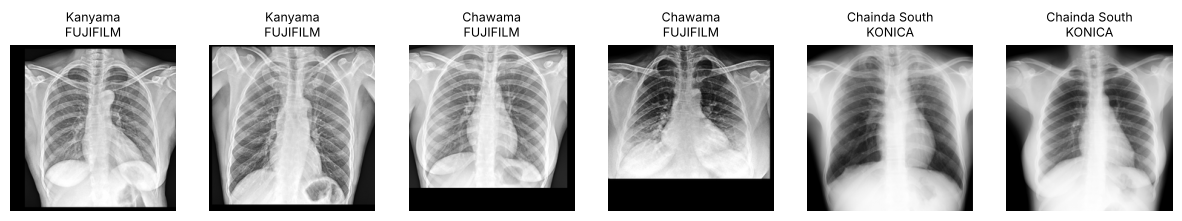

In [3]:
samples = pd.concat([people[people.clinic == c].head(2) for c in ["Kanyama", "Chawama", "Chainda South"]])
try:
    import pydicom

    tb.download_images(files=samples.file.tolist())
    fig, axes = plt.subplots(1, 6, figsize=(15, 3))
    for ax, row in zip(axes, samples.itertuples()):
        ax.imshow(tb.dicom_to_224(pydicom.dcmread(tb.IMAGES / row.file)), cmap="gray")
        ax.set_title(f"{row.clinic}\n{row.Manufacturer.split()[0]}", fontsize=9)
        ax.set_axis_off()
except Exception as e:
    print("images not available (no internet?); the rest of the notebook doesn't need them:", type(e).__name__)

### What is "photometric interpretation"? (and what is an inversion?)
A DICOM file stores each pixel as a number (here 0–4095). The header field `PhotometricInterpretation` says **how to
turn those numbers into grey**:

| Value | Meaning | Empty air at the edge of the image | Bone |
|---|---|---|---|
| `MONOCHROME2` | small numbers are dark, large numbers are bright (the usual picture convention) | low numbers | high numbers |
| `MONOCHROME1` | the reverse: small numbers are bright, large numbers are dark | high numbers | low numbers |

Two machines can store the *same* X-ray with opposite numbers. A viewer reads the field and flips the
numbers when needed. An **inversion** is that flip: `new = maximum − old`, so black becomes white and white becomes
black. Our pipeline inverts `MONOCHROME1` images and leaves `MONOCHROME2` alone, so the model always sees
bone bright and lungs dark. If a pipeline ignores the field, every image from the other kind of machine reaches
the model as a **photographic negative**: valid numbers, no error, wrong picture.

To check it yourself, look at the header, and at a corner of the image, which is empty air:

2/2 images


,machine,PhotometricInterpretation,"raw value, empty corner","raw value, chest centre"
clinic,,,,
Kanyama,FUJIFILM,MONOCHROME1,4091,931
Chainda South,KONICA,MONOCHROME2,36,3592


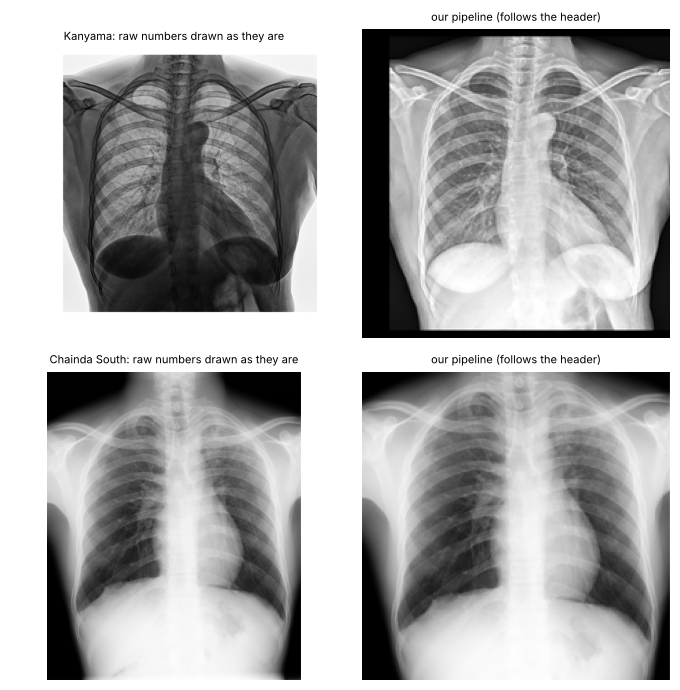

In [4]:
samples2 = pd.concat([people[people.clinic == c].head(1) for c in ["Kanyama", "Chainda South"]])
try:
    import pydicom

    tb.download_images(files=samples2.file.tolist())
    fig, axes = plt.subplots(2, 2, figsize=(7, 7))
    rows = []
    for r, row in enumerate(samples2.itertuples()):
        ds = pydicom.dcmread(tb.IMAGES / row.file)
        raw = ds.pixel_array.astype(float)
        h, w = raw.shape
        rows.append({"clinic": row.clinic, "machine": row.Manufacturer.split()[0],
                     "PhotometricInterpretation": ds.PhotometricInterpretation,
                     "raw value, empty corner": int(raw[:100, :100].mean()),
                     "raw value, chest centre": int(raw[h // 2 - 100:h // 2 + 100, w // 2 - 100:w // 2 + 100].mean())})
        axes[r, 0].imshow(raw, cmap="gray")
        axes[r, 0].set_title(f"{row.clinic}: raw numbers drawn as they are", fontsize=8)
        axes[r, 1].imshow(tb.dicom_to_224(ds), cmap="gray")
        axes[r, 1].set_title("our pipeline (follows the header)", fontsize=8)
        for ax in axes[r]:
            ax.set_axis_off()
    plt.tight_layout()
    display(pd.DataFrame(rows).set_index("clinic"))
except Exception as e:
    print("images not available (no internet?); the rest of the notebook doesn't need them:", type(e).__name__)

The Fujifilm image (`MONOCHROME1`) has **high** numbers in the empty corner: drawn as it is, it is a negative.
The Konica Minolta image (`MONOCHROME2`) has **low** numbers there: drawn as it is, it already looks right. The
header tells you which case you have, without opening an image.

## 2. Step 1: build the model at Kanyama (HIV-negative adults)

70% of Kanyama's HIV-negative participants to train, 30% held out to test. The threshold is chosen to catch
90% of TB cases, using cross-validated predictions on the training set (choosing it on the model's own
training predictions makes it too strict).

In [5]:
train, test = train_test_split(STEP1, test_size=0.3, stratify=y[STEP1], random_state=0)


def new_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.01, class_weight="balanced", max_iter=5000))


p_cv = cross_val_predict(new_model(), X[train], y[train], cv=5, method="predict_proba")[:, 1]
threshold = tb.threshold_for_sensitivity(y[train], p_cv, 0.90)
model = new_model().fit(X[train], y[train])
score = lambda idx: model.predict_proba(X[idx])[:, 1]


def evaluate(sets, scorer=score, thr=None):
    thr = threshold if thr is None else thr
    return pd.DataFrame({name: tb.screening_metrics(y[idx], scorer(idx), thr) for name, idx in sets.items()}).T


results = {"1. Kanyama, HIV-negative (held out)": test}
evaluate(results)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"1. Kanyama, HIV-negative (held out)",155.0,25.0,0.804,0.84,0.515,0.542


ROC-AUC about 0.80; most TB cases caught, at the cost of many false alarms (low specificity). A modest model:
it was trained on about 360 X-rays. For comparison, Google's model on the same people:

In [6]:
google = lambda idx: people.google_score.to_numpy()[idx]
evaluate({"Google's model, Kanyama HIV-negative": STEP1}, scorer=google, thr=0.305)   # 0.305 = the study's threshold

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"Google's model, Kanyama HIV-negative",515.0,82.0,0.903,0.939,0.603,0.483


A much larger model trained on far more data does better. We keep ours: the point of this notebook is what
happens to a model **when it moves**, and Google's model will come back as a comparison.

**Log it.** Parameters, metrics, which data, the model, and a registry alias, as in the EMR demo.

In [7]:
mlflow.set_experiment("tb-screening")
client = mlflow.MlflowClient()
with mlflow.start_run(run_name="v1 Kanyama HIV-negative"):
    mlflow.log_params({"features": "torchxrayvision densenet121-res224-all", "classifier": "logistic C=0.01 balanced",
                       "trained_on": "Kanyama, HIV-negative", "n_train": len(train), "threshold": round(threshold, 4)})
    mlflow.log_metrics({f"step1_{k}": float(v) for k, v in evaluate(results).iloc[0].items() if k not in ("people", "TB cases")})
    info = mlflow.sklearn.log_model(model, name="logistic-on-cxr-features", signature=infer_signature(X[:5], model.predict_proba(X[:5])),
                                    pyfunc_predict_fn="predict_proba", skops_trusted_types=["numpy.dtype"])
version = mlflow.register_model(info.model_uri, "tb-screening").version
client.set_registered_model_alias("tb-screening", "champion", version)
print(f"tb-screening version {version} is @champion")

2026/10/23 15:27:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/23 15:27:14 INFO mlflow.store.db.utils: Updating database tables


2026/10/23 15:27:15 INFO mlflow.tracking.fluent: Experiment with name 'tb-screening' does not exist. Creating a new experiment.


tb-screening version 1 is @champion


Successfully registered model 'tb-screening'.
Created version '1' of model 'tb-screening'.


## The checks we'll run at every new site

Three **label-free** checks, available the day images arrive, and one that needs lab results:

1. **Header check:** does the DICOM header match the reference (step 1's machine)?
2. **Feature drift:** can a classifier tell the new site's image features from step 1's? (ROC-AUC 0.5 = indistinguishable, 1.0 = completely different.)
3. **Flag rate:** what share of people does the model send for a lab test?
4. **Performance** (needs lab results): sensitivity, specificity, ROC-AUC.

In [8]:
reference = people.iloc[train]


def header_check(idx, min_share=0.05):
    """Share of images whose header has a value that was rare (< 5%) or absent in the reference.

    (Kanyama also has a few images from a second machine; a rule of "seen at least once" would accept them.)
    """
    batch = people.iloc[idx]
    out = {}
    for c in ["Manufacturer", "PhotometricInterpretation", "PixelSpacing", "Columns"]:
        usual = reference[c].value_counts(normalize=True)
        out[c] = (~batch[c].isin(usual[usual >= min_share].index)).mean()
    return pd.Series(out, name="share not matching reference")


def feature_drift(idx):
    """How well a classifier separates these images from step 1's training images (ROC-AUC)."""
    both = np.r_[train, idx]
    which = np.r_[np.zeros(len(train)), np.ones(len(idx))]
    return cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=5000)),
                           X[both], which, cv=5, scoring="roc_auc").mean()


def label_free(name, idx):
    return pd.Series({"header mismatch (max over fields)": header_check(idx).max(),
                      "feature drift (ROC-AUC)": feature_drift(idx),
                      "flag rate": (score(idx) >= threshold).mean()}, name=name)


checks = {"1. Kanyama, HIV-negative (held out)": label_free("1", test)}
pd.DataFrame(checks).T

,header mismatch (max over fields),feature drift (ROC-AUC),flag rate
"1. Kanyama, HIV-negative (held out)",0.026,0.472,0.542


(Kanyama's 3%: a few of its images come from a second machine, made by Rayence. Worth knowing; too few to matter.)

## 3. Step 2: a second clinic with the same machine (Chawama)

In [9]:
checks["2. Chawama, HIV-negative"] = label_free("2", STEP2)
pd.DataFrame(checks).T

,header mismatch (max over fields),feature drift (ROC-AUC),flag rate
"1. Kanyama, HIV-negative (held out)",0.026,0.472,0.542
"2. Chawama, HIV-negative",0.000,0.650,0.414


> **PAUSE (2–3 min).** Every check is quiet at Chawama. Would you switch the model on there without waiting for lab results? What would you want to see first?
> Write your answer down before reading on.

Headers match; the features are only mildly distinguishable; the flag rate is similar. Nothing alarming. Then
the lab results:

In [10]:
results["2. Chawama, HIV-negative"] = STEP2
evaluate(results)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"1. Kanyama, HIV-negative (held out)",155.0,25.0,0.804,0.84,0.515,0.542
"2. Chawama, HIV-negative",512.0,41.0,0.735,0.61,0.603,0.414


Performance is lower at Chawama although the images look the same to every check (sensitivity drops; note
the small numbers: 41 TB cases). The checks above look at **images**; they can't see a different
**case mix** (TB prevalence here is half of Kanyama's, and milder disease is harder to see). First lesson:
**passing the input checks does not prove the model works at a new site.** Validate on local lab results
before go-live, even with identical equipment.

## 4. Step 3: a clinic with a different X-ray machine (Chainda South)

In [11]:
checks["3. Chainda South, HIV-negative"] = label_free("3", STEP3)
print(header_check(STEP3).round(2).to_string(), "\n")
pd.DataFrame(checks).T

Manufacturer                 0.99
PhotometricInterpretation    0.99
PixelSpacing                 0.99
Columns                      0.99 



,header mismatch (max over fields),feature drift (ROC-AUC),flag rate
"1. Kanyama, HIV-negative (held out)",0.026,0.472,0.542
"2. Chawama, HIV-negative",0.000,0.650,0.414
"3. Chainda South, HIV-negative",0.993,0.995,0.000


> **PAUSE (2–3 min).** The model flags nobody at Chainda South. Good news (no TB there) or bad news? What would you tell the programme manager today, before any lab results?
> Write your answer down before reading on.

Every label-free check fires: the headers differ, the features are almost perfectly distinguishable,
and the model **flags nobody**. The same question with Evidently (the EMR demo's monitoring tool), on a
10-number summary of the features, for all four groups:

In [12]:
from evidently import DataDefinition, Dataset, Report
from evidently.presets import DataDriftPreset

pca = PCA(n_components=10, random_state=0).fit(X[train])
cols = [f"pc{i + 1}" for i in range(10)]
as_table = lambda idx: Dataset.from_pandas(pd.DataFrame(pca.transform(X[idx]), columns=cols),
                                           data_definition=DataDefinition(numerical_columns=cols))
for name, idx in [("step 1 held out", test), ("step 2 Chawama", STEP2), ("step 3 Chainda South", STEP3), ("step 4 Kanyama HIV+", STEP4)]:
    snap = Report([DataDriftPreset()]).run(as_table(idx), as_table(train))
    drifted = next(m for m in snap.dict()["metrics"] if "DriftedColumnsCount" in m["metric_name"])["value"]
    print(f"{name:22s} {drifted['count']:.0f} of 10 feature summaries drifted")

step 1 held out        0 of 10 feature summaries drifted


step 2 Chawama         6 of 10 feature summaries drifted


step 3 Chainda South   10 of 10 feature summaries drifted


step 4 Kanyama HIV+    5 of 10 feature summaries drifted


Evidently flags Chainda South completely, but also flags several summaries for Chawama and for HIV-positive
patients. With hundreds of images, even small differences pass a statistical test. **Drift means different,
not wrong**, and a count of "drifted columns" doesn't say how different. The classifier check above does:
0.65 and 0.59 (small) against 0.995 (a different world). Set alert thresholds on the size of the difference.

Then the lab results confirm Chainda South:

In [13]:
results["3. Chainda South, HIV-negative"] = STEP3
evaluate(results)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"1. Kanyama, HIV-negative (held out)",155.0,25.0,0.804,0.84,0.515,0.542
"2. Chawama, HIV-negative",512.0,41.0,0.735,0.61,0.603,0.414
"3. Chainda South, HIV-negative",148.0,7.0,0.645,0.00,1.000,0.000


**Every TB case at Chainda South is missed** (only 7 among these participants, but 0 of 7 is no accident). No
error, no crash: the model returns valid probabilities, all close to zero, because the new machine's images
produce features unlike anything it was trained on.

### The quieter version of the same failure

Suppose the pipeline written at Kanyama always inverts images (correct for Fujifilm's `MONOCHROME1`) and
ignores the header. At Chainda South every image then arrives inverted.

> **PAUSE (2–3 min).** Which of our three label-free checks (header, feature drift, flag rate) would catch this bug?
> Write your answer down before reading on.

In [14]:
konica = [i for i in STEP3 if people.PhotometricInterpretation.iloc[i] == "MONOCHROME2"]
bug_features = tb.load_bug_features(people.anon_id.iloc[konica])
bug = lambda idx: model.predict_proba(bug_features)[:, 1]
evaluate({"3. Chainda South, inverted by the pipeline bug": konica}, scorer=bug)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"3. Chainda South, inverted by the pipeline bug",147.0,7.0,0.504,0.286,0.636,0.361


Now the flag rate looks **plausible** (within the range of the other clinics), so a flag-rate monitor would
stay quiet, but the model is no better than a coin toss (ROC-AUC ≈ 0.5). Only the **header check** catches it. That is why image
pipelines must read and respect the header, and why the header check runs first.

### Respond

> **PAUSE (2–3 min).** What are the programme's options at Chainda South? Which would you try first, and what would it cost?
> Write your answer down before reading on.

- **Re-set the threshold from local images** (no labels needed: choose it so the flag rate matches Kanyama's):

In [15]:
flag_rate_site1 = (p_cv >= threshold).mean()
local_threshold = np.quantile(score(STEP3), 1 - flag_rate_site1)
evaluate({"3. Chainda South, local threshold": STEP3}, thr=local_threshold)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"3. Chainda South, local threshold",148.0,7.0,0.645,0.857,0.404,0.608


Flags come back, but ROC-AUC stays low: a threshold cannot fix a model that **ranks** these images badly.
Retraining needs many local labelled images, and Chainda South has only 11 TB cases in total. Google's model,
trained on images from many machines, handles the new vendor much better:

In [16]:
evaluate({"Google's model, Chainda South HIV-negative": STEP3}, scorer=google, thr=0.305)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"Google's model, Chainda South HIV-negative",148.0,7.0,0.829,0.714,0.816,0.209


**Decision:** our model is **not** promoted for Chainda South. Options for the programme: collect a labelled
local sample large enough to retrain and validate, standardise acquisition settings, or use a model trained
on many devices (and still validate it locally).

## 5. Step 4: the same clinic, a different population (HIV-positive adults at Kanyama)

Same machine, same software, same pipeline as step 1. Only the patients differ.

In [17]:
checks["4. Kanyama, HIV-positive"] = label_free("4", STEP4)
pd.DataFrame(checks).T

,header mismatch (max over fields),feature drift (ROC-AUC),flag rate
"1. Kanyama, HIV-negative (held out)",0.026,0.472,0.542
"2. Chawama, HIV-negative",0.000,0.650,0.414
"3. Chainda South, HIV-negative",0.993,0.995,0.000
"4. Kanyama, HIV-positive",0.026,0.593,0.590


> **PAUSE (2–3 min).** Same machine, same pipeline, quiet checks. Is the model fine for HIV-positive patients? How would you find out, and how many patients would you need?
> Write your answer down before reading on.

The label-free checks see little: headers match, the features differ only slightly (less than Chawama's),
the flag rate is similar. Then the lab results:

In [18]:
results["4. Kanyama, HIV-positive"] = STEP4
evaluate(results)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"1. Kanyama, HIV-negative (held out)",155.0,25.0,0.804,0.840,0.515,0.542
"2. Chawama, HIV-negative",512.0,41.0,0.735,0.610,0.603,0.414
"3. Chainda South, HIV-negative",148.0,7.0,0.645,0.000,1.000,0.000
"4. Kanyama, HIV-positive",346.0,52.0,0.743,0.846,0.456,0.590


In [19]:
def bootstrap_auc(idx, scorer, n=1000, seed=0):
    rng, vals = np.random.default_rng(seed), []
    for _ in range(n):
        s = rng.choice(idx, len(idx))
        if 0 < y[s].sum() < len(s):
            vals.append(roc_auc_score(y[s], scorer(s)))
    return "{:.2f} ({:.2f}–{:.2f})".format(roc_auc_score(y[idx], scorer(idx)), *np.percentile(vals, [5, 95]))


pd.DataFrame({"our model": [bootstrap_auc(test, score), bootstrap_auc(STEP4, score)],
              "Google's model": [bootstrap_auc(STEP1, google), bootstrap_auc(STEP4, google)]},
             index=["HIV-negative", "HIV-positive"]).rename_axis("Kanyama: ROC-AUC (90% interval)")

,our model,Google's model
Kanyama: ROC-AUC (90% interval),,
HIV-negative,0.80 (0.71–0.88),0.90 (0.87–0.93)
HIV-positive,0.74 (0.68–0.80),0.82 (0.76–0.87)


In [20]:
evaluate({"Google, Kanyama HIV-negative": STEP1, "Google, Kanyama HIV-positive": STEP4}, scorer=google, thr=0.305)

,people,TB cases,roc_auc,sensitivity,specificity,flag_rate
"Google, Kanyama HIV-negative",515.0,82.0,0.903,0.939,0.603,0.483
"Google, Kanyama HIV-positive",346.0,52.0,0.816,0.808,0.578,0.480


Both models rank HIV-positive patients worse. Google's larger model shows it most clearly: its sensitivity
falls from about 0.94 to 0.81 at the same threshold, at the same clinic, on the same machine. Ours shows the
same direction with wider intervals (only 52 TB cases among HIV-positive participants here).

Why: TB in people living with HIV more often looks atypical or subtle on X-ray, and is more often
smear-negative (fewer bacteria):

In [21]:
people[people.tb == 1].groupby("hiv").smear_all.value_counts(normalize=True).unstack().round(2).rename(
    columns={"neg": "smear-negative", "pos": "smear-positive"})

smear_all,smear-negative,smear-positive
hiv,,
HIV-negative,0.38,0.62
HIV-positive,0.48,0.52


This is **population shift**: the images look normal to every check; the relationship between image and
disease is different. Only lab results reveal it, and in routine screening lab results exist mainly for
**flagged** people, so missed cases rarely show up at all.

**Respond:** evaluate per group before go-live (HIV status, previous TB, sex, age); include enough HIV-positive
patients in training and validation; consider a group-specific threshold (the fairness lesson's tools);
audit a random sample of **non-flagged** people with a lab test.

## Summary: which check caught what

In [22]:
summary = pd.DataFrame(checks).T.join(evaluate(results)[["roc_auc", "sensitivity", "specificity"]])
summary.round(2)

,header mismatch (max over fields),feature drift (ROC-AUC),flag rate,roc_auc,sensitivity,specificity
"1. Kanyama, HIV-negative (held out)",0.03,0.47,0.54,0.80,0.84,0.52
"2. Chawama, HIV-negative",0.00,0.65,0.41,0.74,0.61,0.60
"3. Chainda South, HIV-negative",0.99,0.99,0.00,0.65,0.00,1.00
"4. Kanyama, HIV-positive",0.03,0.59,0.59,0.74,0.85,0.46


| Change | Example | Label-free checks | Lab results |
|---|---|---|---|
| New site, same machine | Chawama | quiet | lower performance (case mix) |
| Different machine (acquisition drift) | Chainda South | header, feature drift, flag rate all fire | every TB case missed |
| Pipeline bug | inverted images | **only the header check** | coin toss |
| Different patients (population shift) | HIV-positive | quiet | lower ROC-AUC and sensitivity |

### What do you do about it?
The label-free checks tell you **which kind of change** you have; what you do next depends on it. In both cases
the deciding question is the same: **is the model's ranking still good (ROC-AUC), or only its cut-off wrong?**

| | First response | Then check on local lab results | If that is not good enough |
|---|---|---|---|
| **Acquisition drift** (new machine or software) | **Fix the pipeline:** follow the header (photometric interpretation, pixel size), standardise size, brightness and contrast, then rerun the header and feature-drift checks | ROC-AUC on a labelled local sample | **Retrain or fine-tune** with labelled images from the new machine, mixed with the old ones |
| **Population shift** (new patients) | **Evaluate per group** on lab results; set the threshold again on local labelled data to reach the target sensitivity | Is ROC-AUC still close to before? If yes, the new threshold is enough | ROC-AUC fell: **retrain** with enough of the new group (and consider a group-specific threshold) |

- **Ranking intact, cut-off wrong:** a new threshold restores sensitivity. It costs more lab tests (a higher flag rate).
- **Ranking worse:** no threshold can fix it. Chainda South shows it: a local threshold finds 6 of 7 TB cases, but ROC-AUC stays at 0.65.
- **Cleaning up the images is necessary but may not be enough.** After fixing the pipeline, test again; do not assume it worked.
- **Either way:** validate on local lab results before go-live, and keep monitoring afterwards.

> **PAUSE (2–3 min).** Think of an AI system your team runs or plans. Which of these four situations is most likely for it, and which check would you add first?
> Write your answer down before reading on.

### What to remember
- A model can fail completely at a new site with no error message.
- **Acquisition drift** is visible without labels: check DICOM headers, feature drift and the flag rate on every batch.
- **Population shift** is invisible to input checks: plan per-group evaluation, enough cases per group, and an audit of non-flagged people.
- Passing the input checks does not prove the model works: validate on local lab results before go-live.
- A threshold cannot fix a model that ranks badly; models trained on many devices are more robust, and still need local validation.
- **Action by kind of change:** acquisition drift → fix the pipeline, then retrain or fine-tune if ROC-AUC is still low; population shift → evaluate per group, set the threshold again locally, and retrain if ROC-AUC fell.